# Part 2 solution: Practice 1: Diabetes Risk

A complete, runnable answer to the 2023-style tasks. Every section is a reusable function: in the exam, change the **CONFIG** cell and run all.

**TASK 0:** Print your student id and full name.

In [1]:
print("st12xxxx")
print("Firstname Lastname")

st12xxxx
Firstname Lastname


In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## CONFIG: the only cell that changes between datasets

In [3]:
PATH = "practice1_diabetes_risk.csv"
TARGET = "Target"

# Text columns that are real categories -> {messy spelling (lowercase): clean value}
CATEGORICAL = {
    "Gender": {"m": "Male", "male": "Male", "f": "Female", "female": "Female"},
}

# Text to replace before pulling numbers out of a column (none needed here)
SPECIAL = {}

# Domain knowledge: values outside these ranges are impossible -> treated as missing
VALID_RANGES = {
    "Height (cm)": (100, 230), "Weight (kg)": (30, 250), "Age (years)": (0, 120),
    "Heart Rate (bpm)": (30, 220), "Exercise Time (min)": (0, None), "Sleep Duration (hours)": (0, 24),
}

# 1. Load the dataset

In [4]:
df = pd.read_csv(PATH)
print(df.shape)
df.head()

(205, 12)


,Gender,Height (cm),Weight (kg),Temperature (C),Age (years),Blood Pressure (mmHg),Cholesterol (mg/dL),Heart Rate (bpm),Blood Sugar (mg/dL),Exercise Time (min),Sleep Duration (hours),Target
0,Male,178.4,74.8,36.2 C,56,109mmHg,215mg/dL,74,149mg/dL,6,4.6,1
1,Male,unknown,73.4 kg,37.1,42 years,123 mmHg,169 mg/dL,73 bpm,111,38,5.9 hours,0
2,Female,156.6 cm,65.2,36.7,43,99 mmHg,110,74 bpm,71,33 min,7.2 hours,0
3,Female,161.4 cm,58.0 kg,36.9,19 years,124,196,92 bpm,122,55 min,7.3,0
4,Female,161.3,NaN,37.2 C,57,128,238,72bpm,abc,20min,5.5,0


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Gender                  205 non-null    str  
 1   Height (cm)             198 non-null    str  
 2   Weight (kg)             198 non-null    str  
 3   Temperature (C)         205 non-null    str  
 4   Age (years)             205 non-null    str  
 5   Blood Pressure (mmHg)   205 non-null    str  
 6   Cholesterol (mg/dL)     197 non-null    str  
 7   Heart Rate (bpm)        205 non-null    str  
 8   Blood Sugar (mg/dL)     198 non-null    str  
 9   Exercise Time (min)     198 non-null    str  
 10  Sleep Duration (hours)  197 non-null    str  
 11  Target                  205 non-null    int64
dtypes: int64(1), str(11)
memory usage: 19.3 KB


# 2. Data cleaning and preprocessing (10 marks)

Order matters: units and string errors must be fixed first, because a column can't be checked for missing values or outliers until it's numeric.

1. Remove exact duplicate rows.
2. Turn common "missing" markers ("", "NA", "?", …) into real NaN.
3. **String errors:** find text with no number in numeric columns; set it to NaN.
4. **Units:** pull the number out of values like "172.4 cm", "$45,000", "12.5%".
5. **Missing values:** median for numeric columns, mode for categorical ones.
6. **Outliers:** IQR method, clipped to the fences.
7. Clean and encode categorical columns.

In [6]:
# 2.0 duplicates
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

# 2.1 common missing-value markers -> NaN
MISSING_TOKENS = ["", "na", "n/a", "nan", "null", "none", "?", "-"]

def standardize_missing(df):
    df = df.copy()
    for c in df.columns:
        df[c] = df[c].map(lambda v: np.nan if isinstance(v, str) and v.strip().lower() in MISSING_TOKENS else v)
    return df

df = standardize_missing(df)

NUMERIC = [c for c in df.columns if c not in CATEGORICAL and c != TARGET]
print("Numeric columns:", NUMERIC)
print("Categorical columns:", list(CATEGORICAL))

Duplicate rows: 5
Shape after removing duplicates: (200, 12)
Numeric columns: ['Height (cm)', 'Weight (kg)', 'Temperature (C)', 'Age (years)', 'Blood Pressure (mmHg)', 'Cholesterol (mg/dL)', 'Heart Rate (bpm)', 'Blood Sugar (mg/dL)', 'Exercise Time (min)', 'Sleep Duration (hours)']
Categorical columns: ['Gender']


In [7]:
# 2.2 helper: extract the number from a messy value
def parse_number(v):
    """'172.4 cm' -> 172.4, '$45,000' -> 45000.0, '12.5%' -> 12.5; text without a number -> NaN."""
    if pd.isna(v):
        return np.nan
    if isinstance(v, (int, float, np.integer, np.floating)):
        return float(v)
    s = str(v).replace(",", "").strip()
    m = re.search(r"[-+]?\d*\.?\d+", s)
    return float(m.group()) if m else np.nan

# 2.3 string errors in numeric columns: text with no number in it
def find_string_errors(df, cols):
    errors = {}
    for c in cols:
        values = df[c].dropna()
        bad = values[values.map(parse_number).isna()]
        if len(bad):
            errors[c] = (len(bad), sorted(bad.astype(str).unique()))
    return errors

string_errors = find_string_errors(df, NUMERIC)
n_string_errors = sum(n for n, _ in string_errors.values())
for col, (n, examples) in string_errors.items():
    print(f"{col}: {n} string errors, e.g. {examples}")
print("Total string errors:", n_string_errors)

Height (cm): 2 string errors, e.g. ['unknown']
Weight (kg): 2 string errors, e.g. ['error', 'unknown']
Cholesterol (mg/dL): 2 string errors, e.g. ['abc', 'unknown']
Heart Rate (bpm): 4 string errors, e.g. ['abc', 'unknown']
Blood Sugar (mg/dL): 2 string errors, e.g. ['##', 'abc']
Exercise Time (min): 2 string errors, e.g. ['##', 'unknown']
Sleep Duration (hours): 2 string errors, e.g. ['##', 'error']
Total string errors: 16


**Justification (string errors):** values like "abc" or "unknown" in a numeric column carry no information. Deleting the whole row would also throw away the row's other, valid measurements, so I convert them to NaN and let the missing-value step fill them in. (If only one or two rows were affected, dropping them would also be acceptable.)

In [8]:
# 2.4 separate units from numbers -> proper numeric columns
def to_numeric_columns(df, cols, special=None):
    df = df.copy()
    special = special or {}
    for c in cols:
        col = df[c]
        if c in special:
            col = col.replace(special[c])
        df[c] = col.map(parse_number)           # units stripped, string errors -> NaN
    return df

before = df[NUMERIC].head(3).copy()
df = to_numeric_columns(df, NUMERIC, SPECIAL)
print("Before:")
print(before.to_string())
print("After:")
print(df[NUMERIC].head(3).to_string())
print(df[NUMERIC].dtypes.value_counts())

Before:
  Height (cm) Weight (kg) Temperature (C) Age (years) Blood Pressure (mmHg) Cholesterol (mg/dL) Heart Rate (bpm) Blood Sugar (mg/dL) Exercise Time (min) Sleep Duration (hours)
0       178.4        74.8          36.2 C          56               109mmHg            215mg/dL               74            149mg/dL                   6                    4.6
1     unknown     73.4 kg            37.1    42 years              123 mmHg           169 mg/dL           73 bpm                 111                  38              5.9 hours
2    156.6 cm        65.2            36.7          43               99 mmHg                 110           74 bpm                  71              33 min              7.2 hours
After:
   Height (cm)  Weight (kg)  Temperature (C)  Age (years)  Blood Pressure (mmHg)  Cholesterol (mg/dL)  Heart Rate (bpm)  Blood Sugar (mg/dL)  Exercise Time (min)  Sleep Duration (hours)
0        178.4         74.8             36.2         56.0                  109.0               

In [9]:
# 2.4b impossible values (domain knowledge) -> NaN, so they get imputed like missing values
def apply_valid_ranges(df, ranges):
    df = df.copy()
    for c, (lo, hi) in ranges.items():
        bad = pd.Series(False, index=df.index)
        if lo is not None:
            bad |= df[c] < lo
        if hi is not None:
            bad |= df[c] > hi
        print(f"{c}: {int(bad.sum())} impossible value(s) {df.loc[bad, c].tolist()} -> NaN")
        df.loc[bad, c] = np.nan
    return df

df = apply_valid_ranges(df, VALID_RANGES)

Height (cm): 2 impossible value(s) [17.2, 1724.0] -> NaN
Weight (kg): 1 impossible value(s) [690.0] -> NaN
Age (years): 2 impossible value(s) [-5.0, 230.0] -> NaN
Heart Rate (bpm): 1 impossible value(s) [310.0] -> NaN
Exercise Time (min): 1 impossible value(s) [-30.0] -> NaN
Sleep Duration (hours): 1 impossible value(s) [30.0] -> NaN


In [10]:
# 2.5 missing values
def missing_report(df):
    r = pd.DataFrame({"missing": df.isna().sum(), "percent": (df.isna().mean() * 100).round(1)})
    return r[r["missing"] > 0]

print(missing_report(df))

def fill_missing(df, numeric, categorical, target):
    df = df.copy()
    df = df.dropna(subset=[target])                         # never invent labels
    for c in numeric:
        df[c] = df[c].fillna(df[c].median())                # median: robust to outliers and skew
    for c in categorical:
        df[c] = df[c].fillna(df[c].mode()[0])               # mode: most common category
    return df

df = fill_missing(df, NUMERIC, list(CATEGORICAL), TARGET)
print("Missing after filling:", int(df.isna().sum().sum()))

                        missing  percent
Height (cm)                  12      6.0
Weight (kg)                  10      5.0
Age (years)                   2      1.0
Cholesterol (mg/dL)          10      5.0
Heart Rate (bpm)              5      2.5
Blood Sugar (mg/dL)          10      5.0
Exercise Time (min)          11      5.5
Sleep Duration (hours)       11      5.5
Missing after filling: 0


**Justification (missing values):** I use the **median** for numeric columns because it is not pulled by outliers or skew (the outlier step comes next, and some columns are skewed), and the **mode** for categorical columns. Dropping rows instead would lose a large share of a ~200-row dataset, since the missing cells are spread over many rows.

                column  lower  upper  outliers
           Height (cm) 138.44 196.74         0
           Weight (kg)  34.38 103.98         2
       Temperature (C)  36.00  37.60         4
           Age (years)  -3.00  93.00         0
 Blood Pressure (mmHg)  87.00 159.00         6
   Cholesterol (mg/dL)  95.12 284.12         1
      Heart Rate (bpm)  47.50  99.50         1
   Blood Sugar (mg/dL)  42.50 158.50         2
   Exercise Time (min) -35.50  82.50        16
Sleep Duration (hours)   4.75   9.15         5


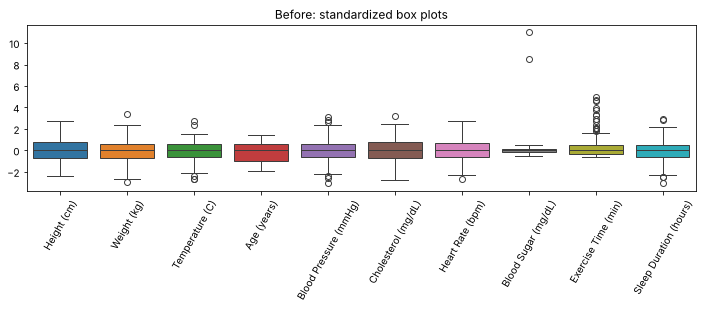

In [11]:
# 2.6 outliers: IQR method
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

def handle_outliers_iqr(df, cols, k=1.5):
    df = df.copy()
    rows = []
    for c in cols:
        lo, hi = iqr_bounds(df[c], k)
        n_out = int(((df[c] < lo) | (df[c] > hi)).sum())
        rows.append((c, round(lo, 2), round(hi, 2), n_out))
        df[c] = df[c].clip(lo, hi)                          # winsorize: keep the row, cap the value
    return df, pd.DataFrame(rows, columns=["column", "lower", "upper", "outliers"])

plt.figure(figsize=(12, 3))
sns.boxplot(data=(df[NUMERIC] - df[NUMERIC].median()) / df[NUMERIC].std())
plt.xticks(rotation=60); plt.title("Before: standardized box plots"); plt.show()

df, outlier_table = handle_outliers_iqr(df, NUMERIC)
print(outlier_table.to_string(index=False))

**Justification (outliers):** two layers. (1) **Impossible values** (a negative exercise time, a cholesterol of 0, an age of 230) are data-entry errors: domain knowledge says they can't happen, so they became NaN in step 2.4b and were imputed. The IQR rule alone would miss some of them, e.g. −30 minutes of exercise sits inside the fences of a skewed column. (2) **Statistical outliers** outside Q1 − 1.5·IQR or Q3 + 1.5·IQR are **clipped** to the fences rather than deleted: the row's other values stay, and one extreme value can't dominate distance-based models (SVM, logistic regression). With ~200 rows, keeping data matters.

In [12]:
# 2.7 categorical columns: unify spellings, then encode
def clean_category(v, mapping):
    if pd.isna(v):
        return v
    s = str(v).strip()
    return mapping.get(s.lower(), s)

for c, mapping in CATEGORICAL.items():
    df[c] = df[c].map(lambda v: clean_category(v, mapping))
    print(c, df[c].value_counts().to_dict())

def encode(df, categorical):
    df = df.copy()
    for c in categorical:
        values = sorted(df[c].unique())
        if len(values) == 2:                                # binary -> 0/1
            df[c] = (df[c] == values[1]).astype(int)
            print(f"{c}: {values[0]} -> 0, {values[1]} -> 1")
        else:                                               # several -> one-hot
            df = pd.get_dummies(df, columns=[c], dtype=int)
    return df

df_clean = encode(df, list(CATEGORICAL))
df_clean.to_csv("cleaned_dataset.csv", index=False)       # deliverable: the cleaned dataset
print(df_clean.shape)
df_clean.head()

Gender {'Male': 103, 'Female': 97}
Gender: Female -> 0, Male -> 1
(200, 12)


,Gender,Height (cm),Weight (kg),Temperature (C),Age (years),Blood Pressure (mmHg),Cholesterol (mg/dL),Heart Rate (bpm),Blood Sugar (mg/dL),Exercise Time (min),Sleep Duration (hours),Target
0,1,178.4,74.8,36.2,56.0,109.0,215.0,74.0,149.0,6.0,4.75,1
1,1,167.4,73.4,37.1,42.0,123.0,169.0,73.0,111.0,38.0,5.90,0
2,0,156.6,65.2,36.7,43.0,99.0,110.0,74.0,71.0,33.0,7.20,0
3,0,161.4,58.0,36.9,19.0,124.0,196.0,92.0,122.0,55.0,7.30,0
4,0,161.3,70.2,37.2,57.0,128.0,238.0,72.0,101.5,20.0,5.50,0


# 3. Class imbalance (7 marks)

### 3.1 Class distribution

        count  percent
Target                
0         154     77.0
1          46     23.0


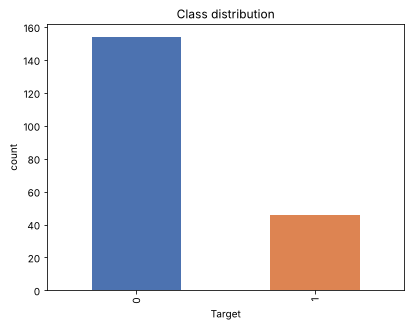

In [13]:
def class_distribution(y, title="Class distribution"):
    counts = y.value_counts().sort_index()
    table = pd.DataFrame({"count": counts, "percent": (counts / counts.sum() * 100).round(1)})
    print(table)
    counts.plot.bar(color=["#4C72B0", "#DD8452"])
    plt.title(title); plt.xlabel(y.name); plt.ylabel("count"); plt.show()
    return table

dist = class_distribution(df_clean[TARGET])

**Why imbalance matters:** with most samples in class 0, a model can score high **accuracy** by mostly predicting 0 while missing the minority class, which is usually the class we care about (at risk, has disease, will default). Training on balanced data and judging with precision, recall, F1 and AUC avoids being fooled by accuracy.

### 3.2 Balancing: SMOTE (written from scratch, so it works even without imbalanced-learn)

I balance **only the training set, after the split** (section 5). Oversampling before splitting would put copies or near-copies of training points into the test set, making the test score too optimistic.

In [14]:
def smote(X, y, k=5, random_state=RANDOM_STATE):
    """Synthetic Minority Over-sampling: new minority points on the line between a
    minority sample and one of its k nearest minority neighbours."""
    rng = np.random.default_rng(random_state)
    X = np.asarray(X, dtype=float)
    y = np.asarray(y)
    classes, counts = np.unique(y, return_counts=True)
    minority = classes[np.argmin(counts)]
    X_min = X[y == minority]
    n_new = counts.max() - counts.min()
    d = ((X_min[:, None, :] - X_min[None, :, :]) ** 2).sum(axis=2)
    np.fill_diagonal(d, np.inf)                              # a point is not its own neighbour
    k = min(k, len(X_min) - 1)
    neighbours = np.argsort(d, axis=1)[:, :k]
    base = rng.integers(0, len(X_min), n_new)
    nb = neighbours[base, rng.integers(0, k, n_new)]
    gap = rng.random((n_new, 1))
    X_new = X_min[base] + gap * (X_min[nb] - X_min[base])
    return np.vstack([X, X_new]), np.concatenate([y, np.full(n_new, minority)])

def random_oversample(X, y, random_state=RANDOM_STATE):
    """Alternative: duplicate random minority rows."""
    rng = np.random.default_rng(random_state)
    X, y = np.asarray(X, dtype=float), np.asarray(y)
    classes, counts = np.unique(y, return_counts=True)
    minority = classes[np.argmin(counts)]
    idx = np.where(y == minority)[0]
    extra = rng.choice(idx, counts.max() - counts.min(), replace=True)
    return np.vstack([X, X[extra]]), np.concatenate([y, y[extra]])

# If imbalanced-learn is installed you can use the library version instead:
# from imblearn.over_sampling import SMOTE
# X_bal, y_bal = SMOTE(random_state=RANDOM_STATE).fit_resample(X_train_s, y_train)

**Justification (SMOTE):** undersampling would throw away most of the majority class from an already small dataset. Random oversampling only duplicates rows, which encourages overfitting to those exact points. SMOTE creates new, slightly different minority samples between real neighbours, so the model sees a fuller picture of the minority class. It is applied after scaling, because it uses distances.

# 4. Exploratory data analysis (5 marks)

### 4.1 Distributions

       Blood Sugar (mg/dL)  Exercise Time (min)
count               200.00               200.00
mean                101.40                27.73
std                  20.07                23.88
min                  49.00                 0.00
25%                  86.00                 8.75
50%                 101.50                21.00
75%                 115.00                38.25
max                 158.50                82.50
Skewness: {'Blood Sugar (mg/dL)': 0.22, 'Exercise Time (min)': 1.06}


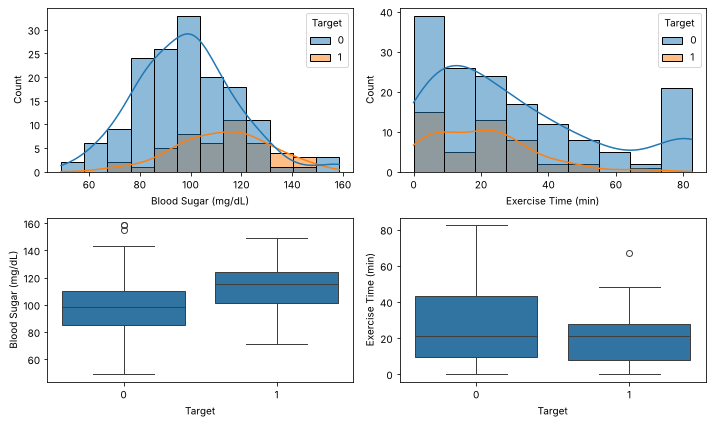

In [15]:
HIST_COLS = ["Blood Sugar (mg/dL)", "Exercise Time (min)"]

fig, axes = plt.subplots(2, len(HIST_COLS), figsize=(5 * len(HIST_COLS), 6))
for j, c in enumerate(HIST_COLS):
    sns.histplot(data=df_clean, x=c, hue=TARGET, kde=True, ax=axes[0, j])
    sns.boxplot(data=df_clean, x=TARGET, y=c, ax=axes[1, j])
plt.tight_layout(); plt.show()

print(df_clean[HIST_COLS].describe().round(2))
print("Skewness:", df_clean[HIST_COLS].skew().round(2).to_dict())

*Write 2–3 sentences:* the shape of each distribution (symmetric or skewed, where the bulk is), whether the clipped values pile up at the fence, and whether the box plots differ between classes (a feature whose median differs a lot between the classes is likely predictive).

### 4.2 Correlation analysis

Correlation with the target:
Blood Sugar (mg/dL)       0.315
Age (years)               0.297
Weight (kg)               0.200
Exercise Time (min)      -0.184
Blood Pressure (mmHg)     0.095
Sleep Duration (hours)    0.081
Height (cm)              -0.079
Temperature (C)          -0.061
Name: Target, dtype: float64
Strongly correlated feature pairs (|r| > 0.7):
none


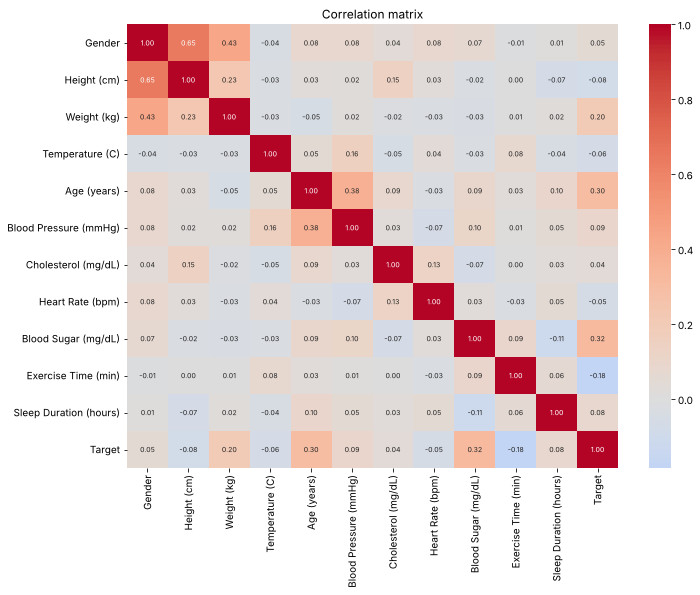

In [16]:
corr = df_clean.corr(numeric_only=True)
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Correlation matrix"); plt.show()

print("Correlation with the target:")
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).head(8))

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
strong = pairs[pairs.abs() > 0.7]
print("Strongly correlated feature pairs (|r| > 0.7):")
print(strong if len(strong) else "none")

*Interpretation:* features most correlated with the target are the most useful single predictors. Strongly correlated feature **pairs** (|r| > 0.7) carry overlapping information (multicollinearity): this makes logistic regression coefficients unstable, and you could drop one of the pair. Tree models are not affected much.

# 5. Scaling (from scratch) and train-test split (5 marks)

**Why scale:** distance- and gradient-based models (SVM, KNN, logistic regression) are dominated by features with large units (cholesterol in hundreds vs temperature in tens) unless all features share a scale. Standardization gives every feature mean 0 and standard deviation 1. The scaler is **fit on the training set only** and then applied to the test set, so no test information leaks into training.

In [17]:
class StandardScalerScratch:
    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.mean_ = X.mean(axis=0)
        self.std_ = X.std(axis=0)
        self.std_[self.std_ == 0] = 1.0                    # constant column: avoid dividing by 0
        return self

    def transform(self, X):
        return (np.asarray(X, dtype=float) - self.mean_) / self.std_

    def fit_transform(self, X):
        return self.fit(X).transform(X)

class MinMaxScalerScratch:
    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.min_, self.max_ = X.min(axis=0), X.max(axis=0)
        self.range_ = np.where(self.max_ - self.min_ == 0, 1.0, self.max_ - self.min_)
        return self

    def transform(self, X):
        return (np.asarray(X, dtype=float) - self.min_) / self.range_

    def fit_transform(self, X):
        return self.fit(X).transform(X)

In [18]:
X = df_clean.drop(columns=[TARGET])
y = df_clean[TARGET].astype(int)
feature_names = X.columns.tolist()

# stratify=y keeps the class ratio the same in train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

ratio = pd.DataFrame({"all": y.value_counts(normalize=True), "train": y_train.value_counts(normalize=True),
                      "test": y_test.value_counts(normalize=True)}).round(3)
print(ratio)

scaler = StandardScalerScratch()
X_train_s = scaler.fit_transform(X_train)                 # fit on train only
X_test_s = scaler.transform(X_test)
print("Train means (should be ~0):", X_train_s.mean(axis=0).round(2)[:5])
print("Train stds  (should be ~1):", X_train_s.std(axis=0).round(2)[:5])

X_bal, y_bal = smote(X_train_s, y_train.values)           # balance the training set only
print("Training classes before SMOTE:", np.bincount(y_train), " after:", np.bincount(y_bal))

         all  train   test
Target                    
0       0.77  0.769  0.775
1       0.23  0.231  0.225
Train means (should be ~0): [0. 0. 0. 0. 0.]
Train stds  (should be ~1): [1. 1. 1. 1. 1.]
Training classes before SMOTE: [123  37]  after: [123 123]


# 6. Model building and evaluation (10 marks)

In [19]:
def evaluate(model, X_te, y_te):
    pred = model.predict(X_te)
    if hasattr(model, "predict_proba"):
        score = model.predict_proba(X_te)[:, 1]
    else:
        score = model.decision_function(X_te)
    return {"accuracy": accuracy_score(y_te, pred),
            "precision": precision_score(y_te, pred, zero_division=0),
            "recall": recall_score(y_te, pred),
            "f1": f1_score(y_te, pred),
            "auc_roc": roc_auc_score(y_te, score)}

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "SVM (RBF)": SVC(probability=True, random_state=RANDOM_STATE),
}

results = {}
for name, model in models.items():
    model.fit(X_bal, y_bal)
    results[name] = evaluate(model, X_test_s, y_test)

summary = pd.DataFrame(results).T.round(3)
summary

,accuracy,precision,recall,f1,auc_roc
Logistic Regression,0.825,0.562,1.000,0.720,0.939
Random Forest,0.875,0.833,0.556,0.667,0.930
SVM (RBF),0.850,0.636,0.778,0.700,0.871


In [20]:
best_name = summary["f1"].idxmax()
print(f"Best model by F1: {best_name} (F1 = {summary.loc[best_name, 'f1']}, AUC = {summary.loc[best_name, 'auc_roc']})")
print("Highest AUC:", summary["auc_roc"].idxmax())

Best model by F1: Logistic Regression (F1 = 0.72, AUC = 0.939)
Highest AUC: Logistic Regression


**Model comparison (fill in from the table):** I rank the models by **F1** and **AUC-ROC**, not accuracy: the test set keeps the original imbalance, so accuracy rewards predicting the majority class. F1 balances precision (how many predicted positives are real) and recall (how many real positives are found); AUC measures how well the model ranks positives above negatives at every threshold. State which model wins and give a reason: e.g. random forests capture non-linear interactions; logistic regression is linear but stable on small data; the RBF SVM sits in between.

# 7. Cross-validation and hyperparameter tuning (10 marks)

### 7.1 5-fold cross-validation

In [21]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

cv_rows = {}
for name, model in models.items():
    cv = cross_validate(model, X_bal, y_bal, cv=skf, scoring=scoring)
    cv_rows[name] = {m: cv[f"test_{m}"].mean() for m in scoring}
    cv_rows[name]["f1_std"] = cv["test_f1"].std()

cv_summary = pd.DataFrame(cv_rows).T.round(3)
cv_summary

,accuracy,precision,recall,f1,roc_auc,f1_std
Logistic Regression,0.805,0.772,0.870,0.818,0.872,0.040
Random Forest,0.837,0.815,0.879,0.843,0.925,0.030
SVM (RBF),0.849,0.806,0.927,0.862,0.926,0.043


**How cross-validation improves evaluation:** one train/test split gives one noisy number that depends on which rows landed in the test set. 5-fold CV trains and tests 5 times, each fold serving once as validation, and averages the scores, so the estimate is more reliable and the standard deviation shows how stable the model is. Stratified folds keep the class ratio in every fold.

*Note:* the folds here are cut from the SMOTE-balanced training set, so synthetic points can sit near their parents across folds, which flatters the CV scores a little. The test set (never balanced) gives the honest number.

### 7.2 Grid search (random forest)

In [22]:
param_grid = {
    "n_estimators": [100, 300],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "max_features": ["sqrt", "log2"],
}
grid = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE), param_grid,
                    scoring="f1", cv=skf, n_jobs=-1, refit=True)
grid.fit(X_bal, y_bal)

print("Best parameters:", grid.best_params_)
print("Best CV F1:", round(grid.best_score_, 3))

tuned = grid.best_estimator_
comparison = pd.DataFrame({"default RF": results["Random Forest"], "tuned RF": evaluate(tuned, X_test_s, y_test)}).T.round(3)
comparison

Best parameters: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 300}
Best CV F1: 0.855


,accuracy,precision,recall,f1,auc_roc
default RF,0.875,0.833,0.556,0.667,0.930
tuned RF,0.875,0.833,0.556,0.667,0.932


**Interpretation:** GridSearchCV tries every combination with 5-fold CV and keeps the best mean F1 (here 2 × 3 × 2 × 2 = 24 combinations × 5 folds). `max_depth` and `min_samples_split` control how much each tree can memorize; the best values are the ones that generalize. Compare the tuned and default rows on the test set: a gain shows the tuning helped; no gain on a small test set is also a valid finding to report.

# 8. Final model evaluation and error analysis (3 marks)

### Confusion matrix from scratch

TN = 24, FP = 7, FN = 0, TP = 9
Precision = TP/(TP+FP) = 0.562
Recall    = TP/(TP+FN) = 1.000
Accuracy  = (TP+TN)/all = 0.825


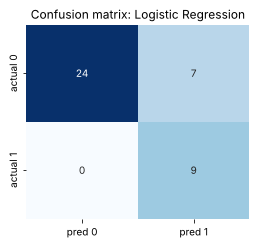

In [23]:
def confusion_matrix_scratch(y_true, y_pred, labels=(0, 1)):
    """Rows = actual class, columns = predicted class."""
    index = {lab: i for i, lab in enumerate(labels)}
    cm = np.zeros((len(labels), len(labels)), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[index[t], index[p]] += 1
    return cm

final_model = tuned if comparison.loc["tuned RF", "f1"] >= summary["f1"].max() else models[best_name]
final_name = "tuned Random Forest" if final_model is tuned else best_name
y_pred = final_model.predict(X_test_s)
cm = confusion_matrix_scratch(y_test.values, y_pred)
tn, fp, fn, tp = cm.ravel()

plt.figure(figsize=(4, 3.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["pred 0", "pred 1"], yticklabels=["actual 0", "actual 1"])
plt.title(f"Confusion matrix: {final_name}"); plt.show()

print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")
print(f"Precision = TP/(TP+FP) = {tp / max(tp + fp, 1):.3f}")
print(f"Recall    = TP/(TP+FN) = {tp / max(tp + fn, 1):.3f}")
print(f"Accuracy  = (TP+TN)/all = {(tp + tn) / cm.sum():.3f}")

**Error analysis:** a **false negative** is a positive case the model missed (an at-risk person labelled safe): usually the costly error here. A **false positive** is a false alarm. To reduce false negatives: lower the decision threshold below 0.5 (trading precision for recall), use `class_weight="balanced"`, collect more minority samples, or engineer stronger features (e.g. BMI from height and weight). To reduce false positives: raise the threshold or add features that separate borderline cases.

# Bonus: feature importance (5 marks)

Age (years)               0.180
Blood Sugar (mg/dL)       0.152
Exercise Time (min)       0.121
Weight (kg)               0.116
Heart Rate (bpm)          0.077
Blood Pressure (mmHg)     0.077
Height (cm)               0.075
Sleep Duration (hours)    0.069
dtype: float64


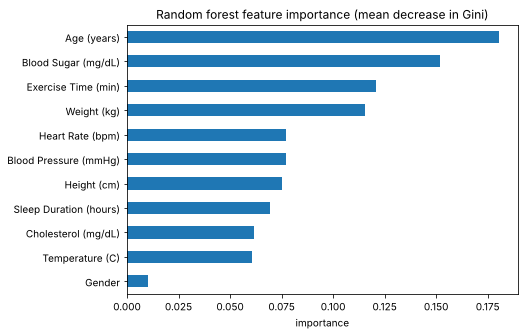

In [24]:
rf_for_importance = tuned
importance = pd.Series(rf_for_importance.feature_importances_, index=feature_names).sort_values()
importance.plot.barh(figsize=(7, 0.35 * len(importance) + 1))
plt.title("Random forest feature importance (mean decrease in Gini)"); plt.xlabel("importance"); plt.show()
print(importance.sort_values(ascending=False).round(3).head(8))

**How to use it:** the top features drive the predictions (check that this makes domain sense). Features with near-zero importance can be dropped to simplify the model, and the top ones suggest where better data or engineered features (ratios, interactions) would help most. Impurity-based importance favours continuous, many-valued features, so confirm with `sklearn.inspection.permutation_importance` if there's time.

# Report summary (generated from the results above)

In [25]:
print(f"""Data cleaning: removed duplicate rows; converted text markers to NaN; extracted numbers from values with units;
turned {n_string_errors} string errors into NaN; filled numeric gaps with the median and categorical gaps with the mode;
clipped outliers to the IQR fences; encoded the categorical columns. Cleaned shape: {df_clean.shape}.

Class balance: {dist['percent'].to_dict()} (percent). Balanced the training set with SMOTE: {np.bincount(y_bal).tolist()}.

Test-set results:
{summary.to_string()}

Best model by F1: {best_name}. Tuned random forest: {grid.best_params_} (CV F1 {grid.best_score_:.3f}).
Final model ({final_name}) confusion matrix: TN={tn}, FP={fp}, FN={fn}, TP={tp}.
Top features: {', '.join(importance.sort_values(ascending=False).index[:3])}.""")

Data cleaning: removed duplicate rows; converted text markers to NaN; extracted numbers from values with units;
turned 16 string errors into NaN; filled numeric gaps with the median and categorical gaps with the mode;
clipped outliers to the IQR fences; encoded the categorical columns. Cleaned shape: (200, 12).

Class balance: {0: 77.0, 1: 23.0} (percent). Balanced the training set with SMOTE: [123, 123].

Test-set results:
                     accuracy  precision  recall     f1  auc_roc
Logistic Regression     0.825      0.562   1.000  0.720    0.939
Random Forest           0.875      0.833   0.556  0.667    0.930
SVM (RBF)               0.850      0.636   0.778  0.700    0.871

Best model by F1: Logistic Regression. Tuned random forest: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 300} (CV F1 0.855).
Final model (Logistic Regression) confusion matrix: TN=24, FP=7, FN=0, TP=9.
Top features: Age (years), Blood Sugar (mg/dL), Exercise Time (min).
